In [1]:
from spp_extended_theory.Libs.libMaterials import *
from spp_extended_theory.Libs.libImportOpticalData import *

In [2]:
epsAir=1.
NumWavelengths=300
wavelengths = np.linspace(310.5e-9, 0.8e-6, NumWavelengths)
fraction=1 #fraction of SLG: 0% is Au. 100% is SLG. (99% is Mario-certified)
NumberOfLayers = 1 #Multilayer model: number of layer per medium

# Import SLG data

importFromNKtable: Generating new wavelength mesh: (3.105e-07, 4.6078999999999995e-06)
New wavelength mesh has 10000 rows.
importFromNKtable: Interpolated permittivity at [310.5        312.13712375 313.77424749 315.41137124 317.04849498
 318.68561873 320.32274247 321.95986622 323.59698997 325.23411371
 326.87123746 328.5083612  330.14548495 331.7826087  333.41973244
 335.05685619 336.69397993 338.33110368 339.96822742 341.60535117
 343.24247492 344.87959866 346.51672241 348.15384615 349.7909699
 351.42809365 353.06521739 354.70234114 356.33946488 357.97658863
 359.61371237 361.25083612 362.88795987 364.52508361 366.16220736
 367.7993311  369.43645485 371.0735786  372.71070234 374.34782609
 375.98494983 377.62207358 379.25919732 380.89632107 382.53344482
 384.17056856 385.80769231 387.44481605 389.0819398  390.71906355
 392.35618729 393.99331104 395.63043478 397.26755853 398.90468227
 400.54180602 402.17892977 403.81605351 405.45317726 407.090301
 408.72742475 410.36454849 412.00167224 

  matplotlib.font_manager - _findfont_cached - WARNING - findfont: Font family ['sans-serif'] not found. Falling back to DejaVu Sans.
  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


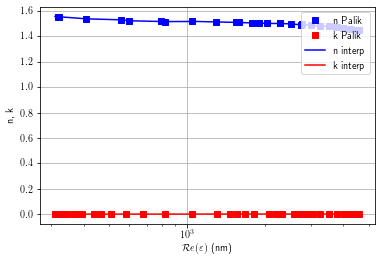

In [3]:
folder="/home/thibault.derrien/Documents/spp-extended-theory/spp_extended_theory/SimpleSPP/Database/"
filename="SLG-Rubin1985"
epsSLG = importFromNKtable(wavelengths, folder, filename, plotting=1, unit=1E-6)

# Defining the 4-layer system

In [4]:
epsSiO2 = ImportPalikDatabase_epsilon_fromNK(wavelengths, "SiO2-Palik")
epsAu   = ImportPalikDatabase_epsilon_fromNK(wavelengths, "Au-Palik")
epsAg   = ImportPalikDatabase_epsilon_fromNK(wavelengths, "Ag-Palik")

In [5]:
eps1=epsAir
eps2=epsSLG
eps3=libMaterials.MaxwellGarnett2(epsAu, epsSLG, fraction) #fraction of SLG
eps4=epsSLG
thickness2=400e-9 #Mario-certified
thickness3=400e-9

# 4-layer model of homogeneous layers

In [6]:
R_4layersModel = TriLayerReflectivity(wavelengths, eps1, eps2, eps3, eps4, thickness2, thickness3)

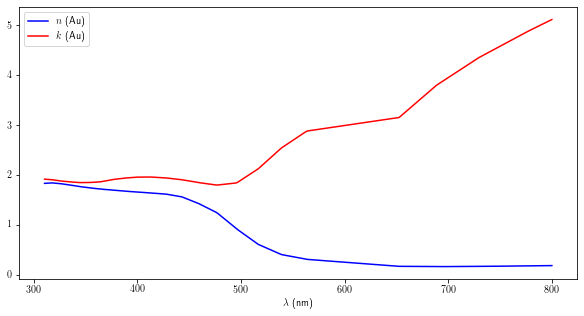

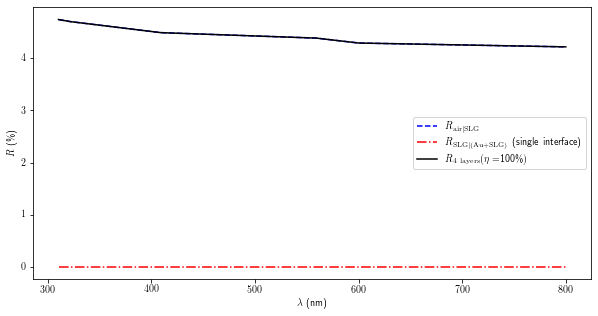

In [7]:
import matplotlib.pyplot as plt

n=np.sqrt(epsAu).real
k=np.sqrt(epsAu).imag

plt.figure(figsize=(10,5))
plt.xlabel(r"$\lambda$ (nm)")
plt.plot(1E9*wavelengths, n, "b-", label=r"$n$ (Au)")
plt.plot(1E9*wavelengths, k, "r-", label=r"$k$ (Au)")
plt.legend(loc="best")
plt.show()

# r_12=ComplexReflectivity(epsAir, epsSiO2)
r_12=ComplexReflectivity(epsAir, epsSLG)
R_12=(r_12*np.conj(r_12)).real

r_23=ComplexReflectivity(epsSLG, epsAu)
R_23=(r_23*np.conj(r_23)).real

# r_23_mixed=ComplexReflectivity(epsSiO2, eps3)
r_23_mixed=ComplexReflectivity(epsSLG, eps3)
R_23_mixed=(r_23_mixed*np.conj(r_23_mixed)).real

plt.figure(figsize=(10,5))
plt.plot(1E9*wavelengths, 100*R_12, "b--", label=r"$R_{\mathrm{air|SLG}}$")
# plt.plot(1E9*wavelengths, 100*R_23, "r--", label=r"$R_{\mathrm{SLG|Au}}$")
plt.plot(1E9*wavelengths, 100*R_23_mixed, "r-.", label=r"$R_{\mathrm{SLG|(Au+SLG)}}$ (single interface)")
plt.plot(1E9*wavelengths, 100*R_4layersModel, "k-", label=r"$R_{\mathrm{4\ layers}}(\eta=$"+str(100*fraction)+"\%$)$")
plt.xlabel(r"$\lambda$ (nm)")
plt.ylabel(r"$R$ (\%)")
plt.legend(loc="best")
plt.show()

In [8]:
!pwd

/home/thibault.derrien/Documents/octopus-slabs/Maths/Tibo-biatrisrv/Plasmonics


# Layer with a distribution

This requires multilayer reflectivity with a large number of layers. 

In [9]:
thickness2, thickness3

(4e-07, 4e-07)

## Definition of the mesh

In [10]:
# Create mesh
epsilon=[]
mesh=[]

# meshOut = np.linspace(0, 0, NumberOfLayers, endpoint=False)
# mesh.append(meshOut) #external medium is recorded at position zero

meshSLG = np.linspace(0, thickness2, NumberOfLayers, endpoint=False)
mesh.append(meshSLG)

meshAuLayer = np.linspace(thickness2, thickness2+thickness3, NumberOfLayers, endpoint=False)
mesh.append(meshAuLayer)

meshSLG2 = np.linspace(thickness2+thickness3, 500e-6, NumberOfLayers, endpoint=True)
mesh.append(meshSLG2)

In [11]:
print(len(meshSLG), len(meshAuLayer), len(meshSLG2))

1 1 1


In [12]:
np.shape(mesh)

(3, 1)

In [13]:
mesh

[array([0.]), array([4.e-07]), array([8.e-07])]

In [14]:
# epsilon = np.asfarray(epsilon)
mesh=np.asfarray(mesh)
mesh=mesh.flatten()

## Definition of $\varepsilon$ distribution

In [15]:
np.arange(0,len(meshSLG))

array([0])

In [16]:
np.arange(len(meshSLG), len(meshSLG)+len(meshAuLayer))

array([1])

In [17]:
np.arange(len(meshSLG)+len(meshAuLayer), len(meshSLG)+len(meshAuLayer)+len(meshSLG2))

array([2])

In [18]:
# epsilon.append([epsAir]) #external medium matters
for idx in np.arange(0,len(meshSLG)):
    epsilon.append(eps2)
for idx in np.arange(len(meshSLG), len(meshSLG)+len(meshAuLayer)):
    epsilon.append(eps3) #replace with the distribution provided by Mario
for idx in np.arange(len(meshSLG)+len(meshAuLayer), len(meshSLG)+len(meshAuLayer)+len(meshSLG2)):
    epsilon.append(eps4)

In [19]:
mesh

array([0.e+00, 4.e-07, 8.e-07])

In [20]:
len(wavelengths)

300

In [21]:
epsilon = np.asfarray(epsilon, dtype=complex)

In [22]:
# type(epsilon)

In [23]:
R_multi=MultilayerReflectance(wavelengths, epsilon, mesh, epsOut=epsAir)

NumCellsZ= 2
Layer  1


In [24]:
np.shape(R_multi)

(300,)

In [25]:
np.shape(epsilon)

(3, 300)

In [26]:
np.shape(epsilon), np.shape(mesh)

((3, 300), (3,))

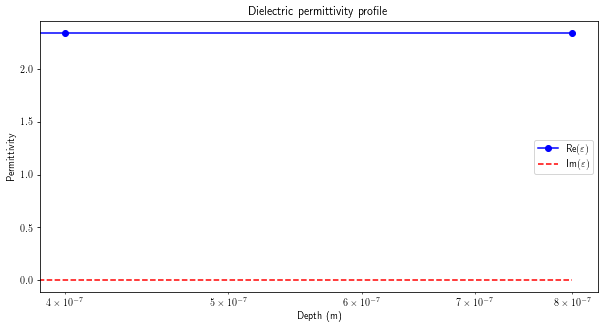

In [27]:
plt.figure(figsize=(10,5))
plt.title("Dielectric permittivity profile")
plt.semilogx(mesh, np.real(epsilon[:,len(wavelengths)//2]), "b-o", label=r"Re$(\varepsilon)$")
plt.semilogx(mesh, np.imag(epsilon[:,len(wavelengths)//2]), "r--", label=r"Im$(\varepsilon)$")
plt.xlabel("Depth (m)")
plt.ylabel("Permittivity")
plt.legend(loc="best")
plt.show()

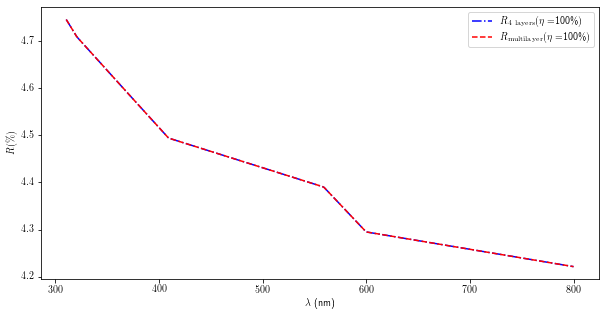

'plt.figure(figsize=(10,5))\n# plt.plot(wavelengths*1E9, 100*R_4layersModel, "b-.", label=r"$R_{\\mathrm{4\\ layers}}(\\eta=$"+str(100*fraction)+"\\%$)$")\nplt.plot(wavelengths*1E9, 100*R_multi, "r-", label=r"$R_{\\mathrm{multilayer}}(\\eta=$"+str(100*fraction)+"\\%$)$")\nplt.xlabel(r"$\\lambda$ (nm)")\nplt.ylabel(r"$R(\\%)$")\nplt.legend()\nplt.show()'

In [28]:
plt.figure(figsize=(10,5))
plt.plot(wavelengths*1E9, 100*R_4layersModel, "b-.", label=r"$R_{\mathrm{4\ layers}}(\eta=$"+str(100*fraction)+"\%$)$")
plt.plot(wavelengths*1E9, 100*R_multi, "r--", label=r"$R_{\mathrm{multilayer}}(\eta=$"+str(100*fraction)+"\%$)$")
plt.xlabel(r"$\lambda$ (nm)")
plt.ylabel(r"$R(\%)$")
plt.legend()
plt.show()

"""plt.figure(figsize=(10,5))
# plt.plot(wavelengths*1E9, 100*R_4layersModel, "b-.", label=r"$R_{\mathrm{4\ layers}}(\eta=$"+str(100*fraction)+"\%$)$")
plt.plot(wavelengths*1E9, 100*R_multi, "r-", label=r"$R_{\mathrm{multilayer}}(\eta=$"+str(100*fraction)+"\%$)$")
plt.xlabel(r"$\lambda$ (nm)")
plt.ylabel(r"$R(\%)$")
plt.legend()
plt.show()"""

In [29]:
R_multi_4layers = R_multi #backup

Still it should give the very same result. But no. Hence, there must be a mistake in the function coded in Python (but also in C!!). Check in Maple implementation as well. 

In [30]:
np.arange(10,1)

array([], dtype=int64)

In [31]:
list(range(10,1,-1))

[10, 9, 8, 7, 6, 5, 4, 3, 2]

# Introduction of a discontinous distribution of dielectric permittivity

In [32]:
# concentration=np.loadtxt("/home/thibault.derrien/Documents/spp-extended-theory/spp_extended_theory/MultilayerSPP/Garcia-Lechuga/Distribucion_Au_SLG_16.txt"); FileName="old"
concentration=np.loadtxt("/home/thibault.derrien/Documents/spp-extended-theory/spp_extended_theory/MultilayerSPP/Garcia-Lechuga/Au_fraction_depth.txt"); FileName="new"

In [33]:
concentration_shrank=concentration[:-1:] #removes last element, only used to define layer thickness

In [34]:
meshMixedLayer=1E-9*concentration[:,0] #complete, needed
meshMixedLayer_shrank=1E-9*concentration_shrank[:,0] #complete, needed

In [35]:
# FractionMixedLayer=concentration[:,1]

In [36]:
np.shape(epsAu), np.shape(epsSLG)

((300,), (300,))

In [37]:
epsMixedLayer=[]
for layer in enumerate(concentration_shrank):
    epsMixedLayer.append(libMaterials.MaxwellGarnett2(epsAu, epsSLG, 1-layer[1][1])) #fraction of SLG is close to 99%
    # epsMixedLayer.append(libMaterials.MaxwellGarnett2(epsAu, epsSLG, layer[1][1])) #fraction of SLG is close to 1%
print(epsMixedLayer)

[array([2.42451327+1.61718834e-04j, 2.42313556+1.40050697e-04j,
       2.42175823+1.18394852e-04j, 2.4203813 +9.67512982e-05j,
       2.41900475+7.51200368e-05j, 2.4176286 +5.70912904e-05j,
       2.41625284+5.60563551e-05j, 2.41520863+5.50257724e-05j,
       2.41427429+5.39968561e-05j, 2.41334013+5.29683338e-05j,
       2.41240615+5.19402055e-05j, 2.41147235+5.09124713e-05j,
       2.41053873+4.98851311e-05j, 2.40960529+4.82085010e-05j,
       2.40867203+4.13586554e-05j, 2.40773896+3.45114599e-05j,
       2.40680606+2.76669146e-05j, 2.40587334+2.08250194e-05j,
       2.40494081+1.39857744e-05j, 2.40400846+7.14917948e-06j,
       2.40307628+5.05246434e-06j, 2.40214429+5.00720706e-06j,
       2.40121248+4.96196696e-06j, 2.40028085+4.91674404e-06j,
       2.3993494 +4.87153829e-06j, 2.39841813+4.82634972e-06j,
       2.39748704+4.78117833e-06j, 2.39655613+4.73602411e-06j,
       2.3956254 +4.69088707e-06j, 2.39469486+4.64576721e-06j,
       2.39376449+4.60066453e-06j, 2.39283431+4.555579

In [38]:
np.shape(epsMixedLayer), np.shape(meshMixedLayer_shrank)

((26, 300), (26,))

## Definition of the mesh

In [39]:
thickness2=meshMixedLayer[0]

In [40]:
thickness3=meshMixedLayer[-1]-meshMixedLayer[0]

In [41]:
# Create mesh
epsilon=[]
mesh=[]

# meshOut = np.linspace(0, 0, NumberOfLayers, endpoint=False)
# mesh.append(meshOut)

meshSLG = np.linspace(0, thickness2, NumberOfLayers, endpoint=False)
mesh.append(meshSLG)

# meshAuLayer = np.linspace(thickness2, thickness2+thickness3, NumberOfLayers, endpoint=False)
# mesh.append(meshAuLayer)

mesh.append(meshMixedLayer_shrank)

meshSLG2 = np.linspace(thickness2+thickness3, 500e-6, NumberOfLayers, endpoint=True)
mesh.append(meshSLG2)

In [42]:
np.shape(meshSLG), np.shape(meshMixedLayer_shrank), np.shape(meshSLG2), np.shape(mesh)

/home/thibault.derrien/.local/lib/python3.6/site-packages/numpy/core/_asarray.py:83: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray
  return array(a, dtype, copy=False, order=order)


((1,), (26,), (1,), (3,))

In [43]:
meshSLG, meshMixedLayer_shrank, meshSLG2

(array([0.]),
 array([3.22123438e-07, 3.47893313e-07, 3.73663188e-07, 3.99433063e-07,
        4.25202938e-07, 4.50972813e-07, 4.76742688e-07, 5.02512563e-07,
        5.28282438e-07, 5.54052313e-07, 5.79822188e-07, 6.05592063e-07,
        6.31361938e-07, 6.57131813e-07, 6.82901688e-07, 7.08671563e-07,
        7.34441438e-07, 7.60211313e-07, 7.85981188e-07, 8.11751063e-07,
        8.37520938e-07, 8.63290813e-07, 8.89060688e-07, 9.14830563e-07,
        9.40600438e-07, 9.66370313e-07]),
 array([9.92140188e-07]))

In [44]:
mesh=np.concatenate(mesh)

In [45]:
np.shape(mesh)

(28,)

In [46]:
mesh

array([0.00000000e+00, 3.22123438e-07, 3.47893313e-07, 3.73663188e-07,
       3.99433063e-07, 4.25202938e-07, 4.50972813e-07, 4.76742688e-07,
       5.02512563e-07, 5.28282438e-07, 5.54052313e-07, 5.79822188e-07,
       6.05592063e-07, 6.31361938e-07, 6.57131813e-07, 6.82901688e-07,
       7.08671563e-07, 7.34441438e-07, 7.60211313e-07, 7.85981188e-07,
       8.11751063e-07, 8.37520938e-07, 8.63290813e-07, 8.89060688e-07,
       9.14830563e-07, 9.40600438e-07, 9.66370313e-07, 9.92140188e-07])

## Definition of the $\varepsilon$

In [47]:
eps2=np.asarray(eps2, dtype=complex)
eps4=np.asarray(eps4, dtype=complex)

In [48]:
epsMixedLayer=np.asfarray(epsMixedLayer, dtype=complex)

In [49]:
epsMixedLayer_1d=np.ravel(epsMixedLayer)

In [50]:
np.shape(eps2), np.shape((epsMixedLayer_1d)), np.shape(eps4)

((300,), (7800,), (300,))

In [51]:
eps2

array([2.42451327+1.61718834e-04j, 2.42313556+1.40050697e-04j,
       2.42175823+1.18394852e-04j, 2.4203813 +9.67512982e-05j,
       2.41900475+7.51200368e-05j, 2.4176286 +5.70912904e-05j,
       2.41625284+5.60563551e-05j, 2.41520863+5.50257724e-05j,
       2.41427429+5.39968561e-05j, 2.41334013+5.29683338e-05j,
       2.41240615+5.19402055e-05j, 2.41147235+5.09124713e-05j,
       2.41053873+4.98851311e-05j, 2.40960529+4.82085010e-05j,
       2.40867203+4.13586554e-05j, 2.40773896+3.45114599e-05j,
       2.40680606+2.76669146e-05j, 2.40587334+2.08250194e-05j,
       2.40494081+1.39857744e-05j, 2.40400846+7.14917948e-06j,
       2.40307628+5.05246434e-06j, 2.40214429+5.00720706e-06j,
       2.40121248+4.96196696e-06j, 2.40028085+4.91674404e-06j,
       2.3993494 +4.87153829e-06j, 2.39841813+4.82634972e-06j,
       2.39748704+4.78117833e-06j, 2.39655613+4.73602411e-06j,
       2.3956254 +4.69088707e-06j, 2.39469486+4.64576721e-06j,
       2.39376449+4.60066453e-06j, 2.39283431+4.5555790

In [52]:
epsilon=eps2

In [53]:
# epsilon=np.concatenate((eps2, epsMixedLayer[0]))

In [54]:
epsilon

array([2.42451327+1.61718834e-04j, 2.42313556+1.40050697e-04j,
       2.42175823+1.18394852e-04j, 2.4203813 +9.67512982e-05j,
       2.41900475+7.51200368e-05j, 2.4176286 +5.70912904e-05j,
       2.41625284+5.60563551e-05j, 2.41520863+5.50257724e-05j,
       2.41427429+5.39968561e-05j, 2.41334013+5.29683338e-05j,
       2.41240615+5.19402055e-05j, 2.41147235+5.09124713e-05j,
       2.41053873+4.98851311e-05j, 2.40960529+4.82085010e-05j,
       2.40867203+4.13586554e-05j, 2.40773896+3.45114599e-05j,
       2.40680606+2.76669146e-05j, 2.40587334+2.08250194e-05j,
       2.40494081+1.39857744e-05j, 2.40400846+7.14917948e-06j,
       2.40307628+5.05246434e-06j, 2.40214429+5.00720706e-06j,
       2.40121248+4.96196696e-06j, 2.40028085+4.91674404e-06j,
       2.3993494 +4.87153829e-06j, 2.39841813+4.82634972e-06j,
       2.39748704+4.78117833e-06j, 2.39655613+4.73602411e-06j,
       2.3956254 +4.69088707e-06j, 2.39469486+4.64576721e-06j,
       2.39376449+4.60066453e-06j, 2.39283431+4.5555790

In [55]:
for element in enumerate(epsMixedLayer):
    epsilon=np.concatenate((epsilon, element[1]))

In [56]:
epsilon=np.concatenate((epsilon, eps4))

In [57]:
np.shape(epsilon)[0]//NumWavelengths

28

In [58]:
epsilon=np.reshape(epsilon, (np.shape(epsilon)[0]//NumWavelengths,NumWavelengths))

In [59]:
"""# epsilon.append([epsAir]) #external medium matters
for idx in np.arange(0,len(meshSLG)):
    print("Loop SLG1", idx)
    epsilon.append(eps2)
# for idx in np.arange(len(meshSLG), len(meshSLG)+len(meshMixedLayer_shrank)):
epsilon.append((epsMixedLayer)) #replace with the distribution provided by Mario
for idx in np.arange(len(meshSLG)+len(meshMixedLayer_shrank), len(meshSLG)+len(meshMixedLayer_shrank)+len(meshSLG2)):
    print("Loop SLG2", idx)
    epsilon.append(eps4)"""

'# epsilon.append([epsAir]) #external medium matters\nfor idx in np.arange(0,len(meshSLG)):\n    print("Loop SLG1", idx)\n    epsilon.append(eps2)\n# for idx in np.arange(len(meshSLG), len(meshSLG)+len(meshMixedLayer_shrank)):\nepsilon.append((epsMixedLayer)) #replace with the distribution provided by Mario\nfor idx in np.arange(len(meshSLG)+len(meshMixedLayer_shrank), len(meshSLG)+len(meshMixedLayer_shrank)+len(meshSLG2)):\n    print("Loop SLG2", idx)\n    epsilon.append(eps4)'

In [60]:
"""def flatten_list(nested_list):
    flattened_list = []
    for i in nested_list:
        if isinstance(i, list):
            flattened_list.extend(flatten_list(i))
        else:
            flattened_list.append(i)
    return flattened_list"""

'def flatten_list(nested_list):\n    flattened_list = []\n    for i in nested_list:\n        if isinstance(i, list):\n            flattened_list.extend(flatten_list(i))\n        else:\n            flattened_list.append(i)\n    return flattened_list'

In [61]:
epsilon = np.asfarray(epsilon, dtype=complex)

In [62]:
mesh=np.asfarray(mesh)
mesh=mesh.flatten()

## Deducing reflectivity

In [63]:
mesh

array([0.00000000e+00, 3.22123438e-07, 3.47893313e-07, 3.73663188e-07,
       3.99433063e-07, 4.25202938e-07, 4.50972813e-07, 4.76742688e-07,
       5.02512563e-07, 5.28282438e-07, 5.54052313e-07, 5.79822188e-07,
       6.05592063e-07, 6.31361938e-07, 6.57131813e-07, 6.82901688e-07,
       7.08671563e-07, 7.34441438e-07, 7.60211313e-07, 7.85981188e-07,
       8.11751063e-07, 8.37520938e-07, 8.63290813e-07, 8.89060688e-07,
       9.14830563e-07, 9.40600438e-07, 9.66370313e-07, 9.92140188e-07])

In [64]:
epsilon

array([[2.42451327+1.61718834e-04j, 2.42313556+1.40050697e-04j,
        2.42175823+1.18394852e-04j, ..., 2.30207804+7.51399762e-06j,
        2.30193651+7.57420850e-06j, 2.30179479+7.63441535e-06j],
       [2.42451327+1.61718834e-04j, 2.42313556+1.40050697e-04j,
        2.42175823+1.18394852e-04j, ..., 2.30207804+7.51399762e-06j,
        2.30193651+7.57420850e-06j, 2.30179479+7.63441535e-06j],
       [2.42485444+3.99330397e-04j, 2.4234761 +3.77285499e-04j,
        2.42209816+3.55251659e-04j, ..., 2.3025348 +1.28570337e-05j,
        2.30239276+1.28715579e-05j, 2.30225054+1.28866670e-05j],
       ...,
       [2.42487339+4.12533188e-04j, 2.42349503+3.90467352e-04j,
        2.42211705+3.68412506e-04j, ..., 2.30256018+1.31539355e-05j,
        2.30241811+1.31659210e-05j, 2.30227586+1.31785240e-05j],
       [2.42485444+3.99330397e-04j, 2.4234761 +3.77285499e-04j,
        2.42209816+3.55251659e-04j, ..., 2.3025348 +1.28570337e-05j,
        2.30239276+1.28715579e-05j, 2.30225054+1.28866670e-05j]

In [65]:
R_multi_profiled=MultilayerReflectance(wavelengths, epsilon, mesh, epsOut=epsAir)

NumCellsZ= 27
Layer  26
Layer  25
Layer  24
Layer  23
Layer  22
Layer  21
Layer  20
Layer  19
Layer  18
Layer  17
Layer  16
Layer  15
Layer  14
Layer  13
Layer  12
Layer  11
Layer  10
Layer  9
Layer  8
Layer  7
Layer  6
Layer  5
Layer  4
Layer  3
Layer  2
Layer  1


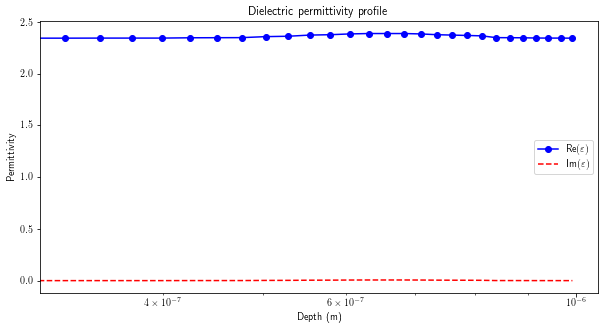

In [66]:
plt.figure(figsize=(10,5))
plt.title("Dielectric permittivity profile")
plt.semilogx(mesh, np.real(epsilon[:,len(wavelengths)//2]), "b-o", label=r"Re$(\varepsilon)$")
plt.semilogx(mesh, np.imag(epsilon[:,len(wavelengths)//2]), "r--", label=r"Im$(\varepsilon)$")
plt.xlabel("Depth (m)")
plt.ylabel("Permittivity")
plt.legend(loc="best")
plt.show()

  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


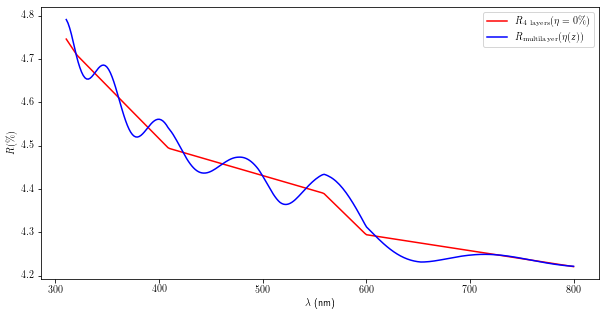

In [68]:
plt.figure(figsize=(10,5))
# plt.plot(wavelengths*1E9, 100*R_4layersModel, "b-.", label=r"$R_{\mathrm{4\ layers}}(\eta=$"+str(100*fraction)+"\%$)$")
plt.plot(wavelengths*1E9, 100*R_multi, "r-", label=r"$R_{\mathrm{4\ layers}}(\eta=0\%)$")
plt.plot(wavelengths*1E9, 100*R_multi_profiled, "b-", label=r"$R_{\mathrm{multilayer}}(\eta(z))$")
plt.xlabel(r"$\lambda$ (nm)")
plt.ylabel(r"$R(\%)$")
plt.legend()
plt.savefig("Garcia-Lechuga-AirSiO2AumixedwithSLG-ProfiledUsingExpInput-ComparedTo4layerModel-"+FileName+".png")
plt.savefig("Garcia-Lechuga-AirSiO2AumixedwithSLG-ProfiledUsingExpInput-ComparedTo4layerModel-"+FileName+".eps")
plt.show()

- This distribution shall be compared to the experimental transmission sent by Mario into slides. 
- The corresponding multilayer transmission shall also be computed.